# MoleCompare — LiH Quantum Energy Experiment

This notebook estimates the ground-state energy of lithium hydride (LiH) using the Variational Quantum Eigensolver (VQE).

**Goal:** Test MoleCompare on a larger molecule than H₂ and compare the quantum result with a classical reference.

# MoleCompare — H₂ Quantum Energy Experiment

This notebook estimates the ground-state energy of the hydrogen molecule (H₂) using the Variational Quantum Eigensolver (VQE).

**Goal:** Demonstrate a quantum-classical workflow for molecular energy estimation and compare the VQE result with a classical reference value.

In [3]:
!pip install -q qiskit qiskit-algorithms qiskit-nature qiskit-nature-pyscf pyscf matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.8 MB/s eta 0:00:00


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit_nature.second_q.transformers import ActiveSpaceTransformer

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP
from qiskit.primitives import StatevectorEstimator
from qiskit_nature.second_q.algorithms import GroundStateEigensolver

In [9]:
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.transformers import ActiveSpaceTransformer

driver = PySCFDriver(
    atom="Li 0.0 0.0 0.0; H 0.0 0.0 1.6",
    unit=DistanceUnit.ANGSTROM,
    basis="sto3g",
    charge=0,
    spin=0,
)

problem = driver.run()

transformer = ActiveSpaceTransformer(
    num_electrons=2,
    num_spatial_orbitals=2
)

problem = transformer.transform(problem)

print("Number of spatial orbitals:", problem.num_spatial_orbitals)
print("Number of particles:", problem.num_particles)

Number of spatial orbitals: 2
Number of particles: (1, 1)


In [12]:
mapper = JordanWignerMapper()

initial_state = HartreeFock(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper,
)

ansatz = UCCSD(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper,
    initial_state=initial_state,
)

print("Problem qubits:", 2 * problem.num_spatial_orbitals)
print("Ansatz qubits:", ansatz.num_qubits)
print("Trainable parameters:", ansatz.num_parameters)

Problem qubits: 4
Ansatz qubits: 4
Trainable parameters: 3


In [13]:
estimator = StatevectorEstimator()
optimizer = SLSQP(maxiter=30, ftol=1e-5)

vqe_solver = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=callback,
)

vqe_solver.initial_point = np.zeros(ansatz.num_parameters)

ground_state_solver = GroundStateEigensolver(mapper, vqe_solver)

result = ground_state_solver.solve(problem)

print(result)

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -8.85432924164
  - computed part:      -1.058109672863
  - ActiveSpaceTransformer extracted energy part: -7.796219568777
~ Nuclear repulsion energy (Hartree): 0.992207270475
> Total ground state energy (Hartree): -7.862121971165
 
=== MEASURED OBSERVABLES ===
 
  0:  # Particles: 2.000 S: 0.000 S^2: 0.000 M: 0.000
 
=== DIPOLE MOMENTS ===
 
~ Nuclear dipole moment (a.u.): [0.0  0.0  3.0235618]
 
  0: 
  * Electronic dipole moment (a.u.): [0.0  0.0  4.928366637811]
    - computed part:      [0.0  0.0  4.932418552014]
    - ActiveSpaceTransformer extracted energy part: [0.0  0.0  -0.004051914203]
  > Dipole moment (a.u.): [0.0  0.0  -1.904804837811]  Total: 1.904804837811
                 (debye): [0.0  0.0  -4.841530517402]  Total: 4.841530517402
 


In [22]:
energy_history = []

def callback(eval_count, parameters, mean, metadata):
    energy_history.append(mean)

estimator = StatevectorEstimator()
optimizer = SLSQP(maxiter=30, ftol=1e-5)

vqe_solver = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=callback,
)

vqe_solver.initial_point = np.zeros(ansatz.num_parameters)

ground_state_solver = GroundStateEigensolver(mapper, vqe_solver)
result = ground_state_solver.solve(problem)

print(result)

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -8.85432924164
  - computed part:      -1.058109672863
  - ActiveSpaceTransformer extracted energy part: -7.796219568777
~ Nuclear repulsion energy (Hartree): 0.992207270475
> Total ground state energy (Hartree): -7.862121971165
 
=== MEASURED OBSERVABLES ===
 
  0:  # Particles: 2.000 S: 0.000 S^2: 0.000 M: 0.000
 
=== DIPOLE MOMENTS ===
 
~ Nuclear dipole moment (a.u.): [0.0  0.0  3.0235618]
 
  0: 
  * Electronic dipole moment (a.u.): [0.0  0.0  4.928366637811]
    - computed part:      [0.0  0.0  4.932418552014]
    - ActiveSpaceTransformer extracted energy part: [0.0  0.0  -0.004051914203]
  > Dipole moment (a.u.): [0.0  0.0  -1.904804837811]  Total: 1.904804837811
                 (debye): [0.0  0.0  -4.841530517402]  Total: 4.841530517402
 


In [23]:
lih_vqe_energy = result.total_energies[0]

print("LiH VQE Total Ground-State Energy:", lih_vqe_energy, "Hartree")

LiH VQE Total Ground-State Energy: -7.862121971164755 Hartree


In [24]:
from qiskit_algorithms import NumPyMinimumEigensolver

exact_solver = NumPyMinimumEigensolver()

exact_ground_state_solver = GroundStateEigensolver(
    mapper,
    exact_solver
)

exact_result = exact_ground_state_solver.solve(problem)

lih_reference_energy = exact_result.total_energies[0]

print("LiH Exact Reference Energy:", lih_reference_energy, "Hartree")

LiH Exact Reference Energy: -7.862128833438596 Hartree


In [25]:
lih_absolute_error = abs(lih_vqe_energy - lih_reference_energy)

print("LiH VQE Energy:", lih_vqe_energy, "Hartree")
print("LiH Reference Energy:", lih_reference_energy, "Hartree")
print("LiH Absolute Error:", lih_absolute_error, "Hartree")
print("Chemical Accuracy Achieved:", lih_absolute_error < 0.0016)

LiH VQE Energy: -7.862121971164755 Hartree
LiH Reference Energy: -7.862128833438596 Hartree
LiH Absolute Error: 6.862273840724242e-06 Hartree
Chemical Accuracy Achieved: True


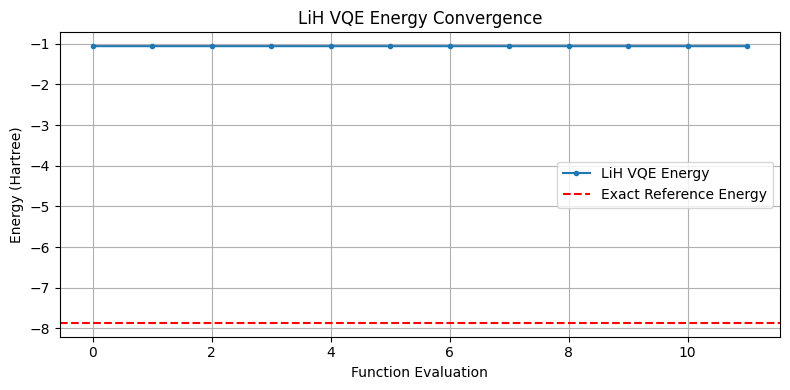

In [26]:
plt.figure(figsize=(8, 4))

plt.plot(
    energy_history,
    marker="o",
    markersize=3,
    label="LiH VQE Energy"
)

plt.axhline(
    lih_reference_energy,
    color="red",
    linestyle="--",
    label="Exact Reference Energy"
)

plt.title("LiH VQE Energy Convergence")
plt.xlabel("Function Evaluation")
plt.ylabel("Energy (Hartree)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("lih_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

In [27]:
from google.colab import files
files.download("lih_convergence.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
reference_energy = -1.13727
absolute_error = abs(vqe_energy - reference_energy)

print("Reference energy:", reference_energy, "Hartree")
print("VQE energy:", vqe_energy, "Hartree")
print("Absolute error:", absolute_error, "Hartree")
print("Chemical accuracy achieved:", absolute_error < 0.0016)

Reference energy: -1.13727 Hartree
VQE energy: -7.862121971164755 Hartree
Absolute error: 6.724851971164755 Hartree
Chemical accuracy achieved: False


In [16]:
energy_history = []

def callback(eval_count, parameters, mean, metadata):
    energy_history.append(mean)

estimator = StatevectorEstimator()
optimizer = SLSQP(maxiter=100)

vqe_solver = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=callback,
)

vqe_solver.initial_point = np.zeros(ansatz.num_parameters)

ground_state_solver = GroundStateEigensolver(mapper, vqe_solver)

result = ground_state_solver.solve(problem)

print(result)

=== GROUND STATE ENERGY ===
 
* Electronic ground state energy (Hartree): -8.854336075605
  - computed part:      -1.058116506828
  - ActiveSpaceTransformer extracted energy part: -7.796219568777
~ Nuclear repulsion energy (Hartree): 0.992207270475
> Total ground state energy (Hartree): -7.86212880513
 
=== MEASURED OBSERVABLES ===
 
  0:  # Particles: 2.000 S: 0.000 S^2: 0.000 M: 0.000
 
=== DIPOLE MOMENTS ===
 
~ Nuclear dipole moment (a.u.): [0.0  0.0  3.0235618]
 
  0: 
  * Electronic dipole moment (a.u.): [0.0  0.0  4.92008367723]
    - computed part:      [0.0  0.0  4.924135591433]
    - ActiveSpaceTransformer extracted energy part: [0.0  0.0  -0.004051914203]
  > Dipole moment (a.u.): [0.0  0.0  -1.89652187723]  Total: 1.89652187723
                 (debye): [0.0  0.0  -4.820477333562]  Total: 4.820477333562
 


In [17]:
vqe_energy = result.total_energies[0]

print("VQE Total Ground-State Energy:", vqe_energy, "Hartree")

VQE Total Ground-State Energy: -7.862128805129891 Hartree


In [18]:
reference_energy = -1.13727
absolute_error = abs(vqe_energy - reference_energy)

print("Reference Energy:", reference_energy, "Hartree")
print("VQE Energy:", vqe_energy, "Hartree")
print("Absolute Error:", absolute_error, "Hartree")
print("Chemical Accuracy Achieved:", absolute_error < 0.0016)

Reference Energy: -1.13727 Hartree
VQE Energy: -7.862128805129891 Hartree
Absolute Error: 6.724858805129891 Hartree
Chemical Accuracy Achieved: False


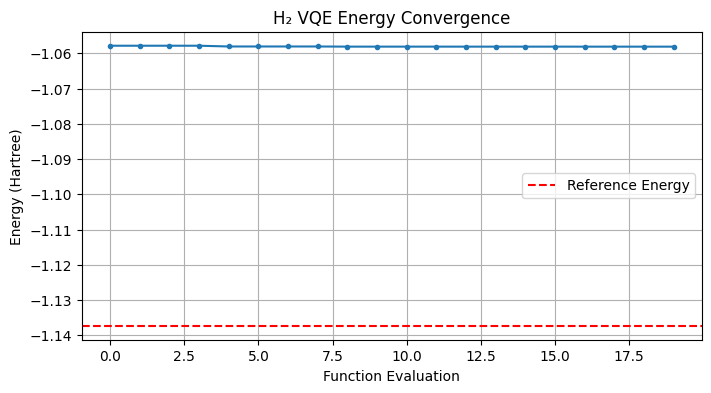

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(energy_history, marker="o", markersize=3)
plt.axhline(reference_energy, color="red", linestyle="--", label="Reference Energy")
plt.title("H₂ VQE Energy Convergence")
plt.xlabel("Function Evaluation")
plt.ylabel("Energy (Hartree)")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
from google.colab import files

files.download("h2_convergence.png")

FileNotFoundError: Cannot find file: h2_convergence.png

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(
    energy_history,
    marker="o",
    markersize=3,
    label="VQE Energy"
)

plt.axhline(
    reference_energy,
    color="red",
    linestyle="--",
    label="Reference Energy"
)

plt.title("H₂ VQE Energy Convergence")
plt.xlabel("Function Evaluation")
plt.ylabel("Energy (Hartree)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("h2_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import files
files.download("h2_convergence.png")

In [ ]:
print("VQE Energy:", vqe_energy)
print("Reference Energy:", reference_energy)
print("Absolute Error:", absolute_error)
print("Chemical Accuracy:", absolute_error < 0.0016)

In [ ]:
energy_history = []

def callback(eval_count, parameters, mean, metadata):
    energy_history.append(mean)

In [ ]:
estimator = StatevectorEstimator()
optimizer = SLSQP(maxiter=200)

vqe_solver = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=callback,
)

vqe_solver.initial_point = np.zeros(ansatz.num_parameters)

ground_state_solver = GroundStateEigensolver(mapper, vqe_solver)

result = ground_state_solver.solve(problem)

print(result)

In [ ]:
lih_vqe_energy = result.total_energies[0]

print("LiH VQE Total Ground-State Energy:", lih_vqe_energy, "Hartree")

In [ ]:
energy_history = []

def callback(eval_count, parameters, mean, metadata):
    energy_history.append(mean)

In [ ]:
estimator = StatevectorEstimator()
optimizer = SLSQP(maxiter=200)

vqe_solver = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    callback=callback,
)

vqe_solver.initial_point = np.zeros(ansatz.num_parameters)

ground_state_solver = GroundStateEigensolver(mapper, vqe_solver)

result = ground_state_solver.solve(problem)

print(result)

In [ ]:
lih_vqe_energy = result.total_energies[0]

print("LiH VQE Total Ground-State Energy:", lih_vqe_energy, "Hartree")